# ROC Curve Comparison of ResNet50, VGG16 and DenseNet121 on BUSI

In this notebook, we compare the three trained classification models (ResNet50, VGG16, DenseNet121) using ROC curves and AUC values. We do not train anything here. We load the saved weights (`.pth` files), run all three models on the **same fixed test set**, and plot their ROC curves in a single figure.

**Background**
- **ROC curve**: plots the True Positive Rate (TPR, i.e. recall) against the False Positive Rate (FPR) as the decision threshold changes from 0 to 1. A curve closer to the top-left corner means a better classifier.
- **AUC**: the area under the ROC curve. AUC = 1.0 is a perfect classifier and AUC = 0.5 is random guessing. It measures how well a model separates the two classes across *all* thresholds, while Accuracy/F1 only reflect a single threshold (0.5).
- This is a binary task (0 = malignant, 1 = benign), so we use one ROC curve per model with **benign as the positive class**.

## 1. Imports and basic settings

This cell imports the required libraries and defines the paths of the model outputs and the image folder. The device is set to GPU if available, otherwise CPU (the login node has no GPU, but inference on 130 images is fast enough on CPU).

In [2]:
import os, numpy as np, pandas as pd, torch, torch.nn as nn
from PIL import Image
from torchvision import models, transforms
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Use GPU if available, otherwise CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Folder containing the 30-epoch weights and predictions of the three models
OUT_DIR = os.path.expanduser("~/Instruction1/outputs")
# Folder containing the BUSI images
IMG_DIR = os.path.expanduser("~/datasets/Dataset_BUSI_with_GT_Clean/images")
print("device:", device)

device: cpu


## 2. Load the fixed test set and preprocess the images

To guarantee a fair comparison, all three models must be evaluated on exactly the same test images. The image names and true labels are read from a saved prediction file (`test_predictions_resnet50.csv`); the three models share the same train/test split.

Each image is preprocessed in the same way as during training: resized to **224×224**, converted to a tensor, and normalized with the ImageNet mean and standard deviation.

In [3]:
# Read the test image names and true labels (0 = malignant, 1 = benign)
test_df = pd.read_csv(os.path.join(OUT_DIR, "test_predictions_resnet50.csv"))
y_true = test_df["True"].values

# Same preprocessing as in the training scripts
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# Load all test images into one tensor
images = torch.stack([
    preprocess(Image.open(os.path.join(IMG_DIR, f)).convert("RGB"))
    for f in test_df["Image"]
])
print(images.shape)   # expected: [130, 3, 224, 224]

torch.Size([130, 3, 224, 224])


## 3. Rebuild the models, load the trained weights and compute probabilities

The `.pth` files only store the weights, so we first rebuild each architecture with the final layer replaced by a 2-class linear layer (the same as in training), then load the saved weights.

For each model we run inference in small batches and apply **softmax** to the output logits to get the probability of each class. ROC curves need these probabilities, not just the predicted labels. We slice batches manually instead of using a DataLoader to avoid using shared memory (`/dev/shm`) on the login node.

In [4]:
def build_model(name):
    """Create the architecture with a 2-class output layer (no pretrained weights needed here)."""
    if name == "resnet50":
        m = models.resnet50(weights=None)
        m.fc = nn.Linear(m.fc.in_features, 2)
    elif name == "vgg16":
        m = models.vgg16(weights=None)
        m.classifier[6] = nn.Linear(m.classifier[6].in_features, 2)
    elif name == "densenet121":
        m = models.densenet121(weights=None)
        m.classifier = nn.Linear(m.classifier.in_features, 2)
    return m

@torch.no_grad()
def get_probs(name):
    """Load the trained weights of one model and return softmax probabilities, shape [N, 2]."""
    m = build_model(name)
    m.load_state_dict(torch.load(os.path.join(OUT_DIR, f"{name}_busi.pth"), map_location="cpu"))
    m.to(device).eval()                       # eval mode: disable dropout / use BN running stats
    probs = []
    for i in range(0, len(images), 16):       # batch size 16
        logits = m(images[i:i+16].to(device))
        probs.append(torch.softmax(logits, dim=1).cpu())
    return torch.cat(probs).numpy()

probs = {n: get_probs(n) for n in ["resnet50", "vgg16", "densenet121"]}

## 4. Sanity check

Before plotting, we verify that the probabilities are correct. The class predicted from the probabilities (`argmax`) should match the predictions saved by the training script (`test_predictions_*.csv`). The agreement should be 1.0000 (or extremely close; tiny CPU/GPU numerical differences may change at most one image). A clearly lower value would indicate a problem with preprocessing or with the loaded weights.

In [5]:
for n, p in probs.items():
    csv_pred = pd.read_csv(os.path.join(OUT_DIR, f"test_predictions_{n}.csv"))["Pred"].values
    agree = (p.argmax(1) == csv_pred).mean()
    print(f"{n}: agreement with saved predictions = {agree:.4f}")

resnet50: agreement with saved predictions = 1.0000
vgg16: agreement with saved predictions = 1.0000
densenet121: agreement with saved predictions = 1.0000


## 5. ROC curves and AUC values

For each model, `roc_curve` computes the FPR and TPR at every possible threshold using the probability of the positive class (benign, column 1). `auc` then computes the area under the curve. The three curves are drawn in one figure, together with the diagonal line that represents random guessing (AUC = 0.5). The figure is also saved to the outputs folder.

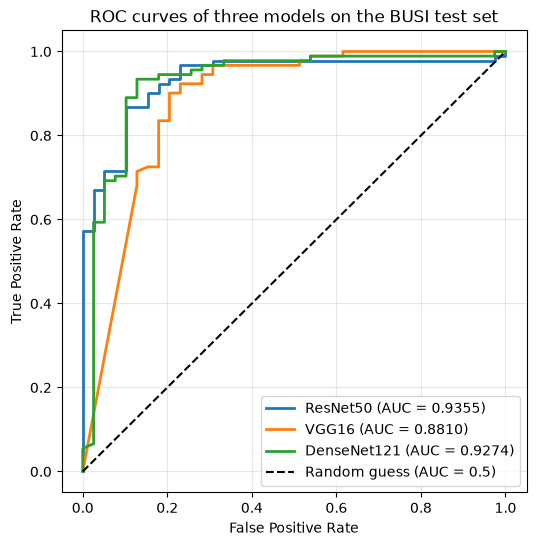

{'resnet50': 0.9354747816286277, 'vgg16': 0.8809523809523809, 'densenet121': 0.9274443505212736}


In [7]:
names = {"resnet50": "ResNet50", "vgg16": "VGG16", "densenet121": "DenseNet121"}
auc_values = {}

plt.figure(figsize=(6, 6))
for n, p in probs.items():
    fpr, tpr, _ = roc_curve(y_true, p[:, 1])      # p[:, 1] = probability of benign
    auc_values[n] = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f"{names[n]} (AUC = {auc_values[n]:.4f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curves of three models on the BUSI test set")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.savefig(os.path.join(OUT_DIR, "roc_comparison.png"), dpi=200, bbox_inches="tight")
plt.show()

print(auc_values)

## 6. Findings and Conclusion

**Findings**
- AUC values: ResNet50 = 0.9355, VGG16 = 0.8810, DenseNet121 = 0.9274. The ranking by AUC is ResNet50 > DenseNet121 > VGG16.
- ResNet50 and DenseNet121 are very close (AUC difference of about 0.008). Their curves rise steeply at low FPR (below 0.1) and overlap closely above FPR = 0.3. ResNet50 is higher in the very low FPR region (about 57% TPR at FPR near 0), while DenseNet121 is slightly higher between FPR 0.1 and 0.2.
- VGG16 is clearly the weakest. Its curve rises more slowly and stays below the other two for FPR from about 0.05 to 0.3, meaning it needs more false positives to reach the same sensitivity. It only catches up when FPR exceeds roughly 0.3.
- The AUC ranking is not fully consistent with the threshold-based metrics. DenseNet121 has the best Accuracy (0.9154) and macro F1 (0.9000), followed by ResNet50 (0.8923 / 0.8718) and VGG16 (0.8692 / 0.8381). This is possible because Accuracy and F1 are measured at a single threshold (0.5), while AUC summarizes performance over all thresholds.

**Conclusion**
- ResNet50 and DenseNet121 achieve similar and the best discrimination between malignant and benign tumors. ResNet50 has the highest AUC, while DenseNet121 has the best Accuracy and F1 at the default threshold. VGG16 performs worst on every metric.
- Limitations: the test set contains only 130 images (39 malignant, 91 benign) and each model was trained only once. The gap between ResNet50 and DenseNet121 is small and may not be statistically meaningful, so we should not claim that one is definitively better. Repeating training with different random seeds would give a more reliable comparison.